# Imports

In [1]:
import pandas as pd
import numpy as np
from itertools import combinations, zip_longest
from glob import glob
from pathlib import Path

In [2]:
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
from statannotations.Annotator import Annotator  # puts significance values on box-type plots

In [3]:
from skbio.stats.composition import clr, multiplicative_replacement

In [4]:
%matplotlib inline
sns.set(palette='muted', style='whitegrid', context='paper', font_scale=1.5)
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']
plt.rcParams['svg.fonttype'] = 'none'  # render SVG text as text, not curves

## Plot function

In [5]:
def diff_plot(data: pd.DataFrame, x: str, n=20, ax=None) -> mpl.axes.Axes:
    """
        >>> diff_plot(log_fold_change_table, x_column, number_of_top_entries_to_show)
        generates a horizontal bar plot of differential abundance
    """
    if x not in data.columns:
        raise AttributeError(f'{x} not in DataFrame columns')
    cmap = mpl.cm.get_cmap('bwr') # Blue-white-red gradient
    data = data.sort_values(x)
    # generate a palette for each X value for it's relative position along the gradient
    data_max = data[x].max()
    data_min = data[x].min()
    xrange = data[x].apply(lambda n: abs(n)/data_max if n>=0 else abs(n)/data_min)
    xrange = (xrange+1.0)/2
    xpalette = dict(zip(xrange.index, xrange.apply(lambda x:cmap(x))))
    # get the top_N items and massage the data into the proper form
    if n < len(data):
        top_n = pd.concat([data[:int(n/2)], data[-int(n/2):]])
    else:
        top_n = data
    yname = top_n.index.name
    top_n = top_n.reset_index()
    if not yname or yname == 'index':
        top_n = top_n.rename({'index':'items'}, axis='columns')
        yname = 'items'
    
    # build the plot
    if not ax:
        ax = plt.gca()
    return sns.barplot(
        data=top_n,
        x=x,
        y=yname,
        palette=xpalette,
        ax = ax
    )

# LFC Tables

In [7]:
lfc_tables = sorted((Path(p) for p in glob('/mnt/zarrinpar/scratch/sfloresr/AD_EM/metagenomics/aldex/all.species*')))

In [11]:
display_orders = (
    ('Ntg.ALF', 'Tg.ALF'),
    ('Tg.TRF', 'Tg.ALF'),
    ('Ntg.ALF', 'Tg.TRF')
)

print(f'columns[2]: {lfc.columns[2]}, columns[3]: {lfc.columns[3]}')
print(f'left: {left}, right: {right}')
print(f'in display_orders: {(left, right) in display_orders}')
print(f'display_orders: {display_orders}')

columns[2]: we.eBH, columns[3]: wi.ep
left: , right: 
in display_orders: False
display_orders: (('Ntg.ALF', 'Tg.ALF'), ('Tg.TRF', 'Tg.ALF'), ('Ntg.ALF', 'Tg.TRF'))


Ntg.ALF Tg.ALF
89


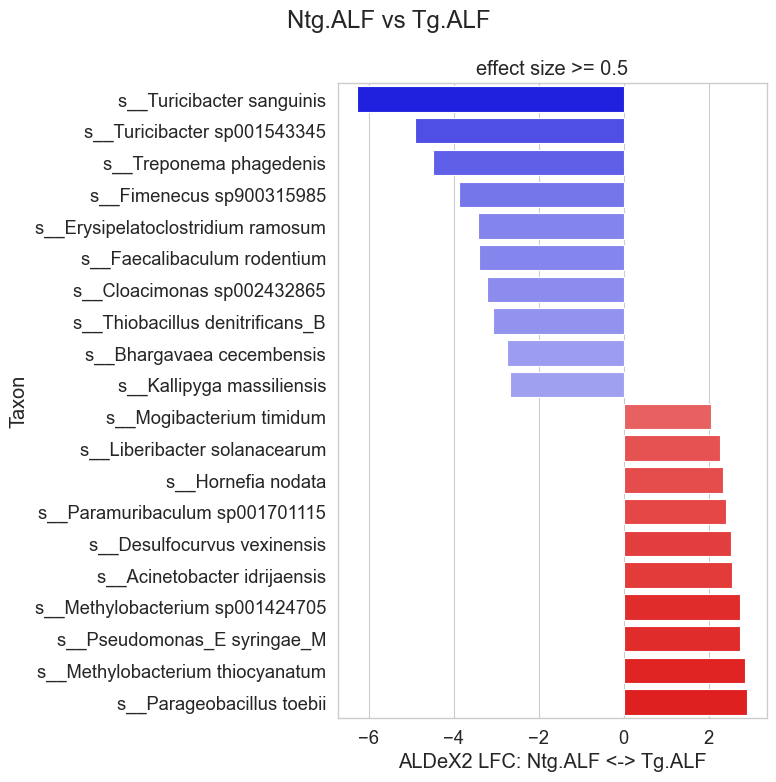

3


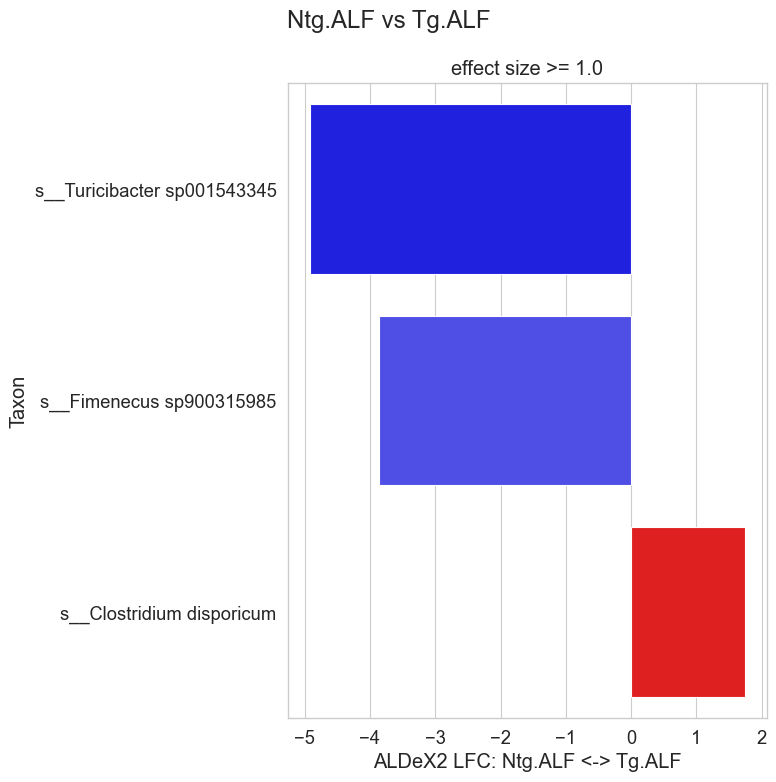

Ntg.ALF Tg.TRF
462


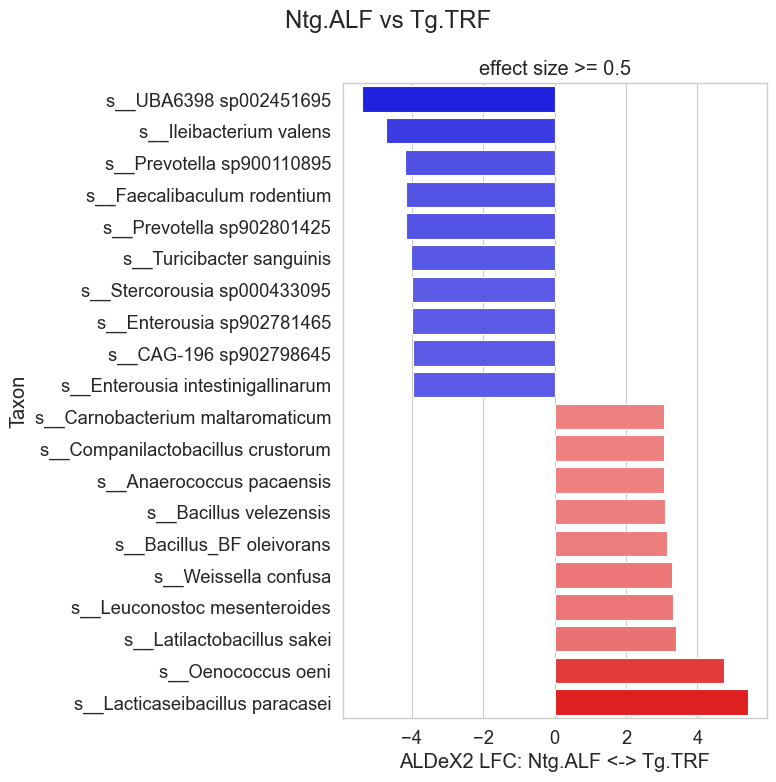

184


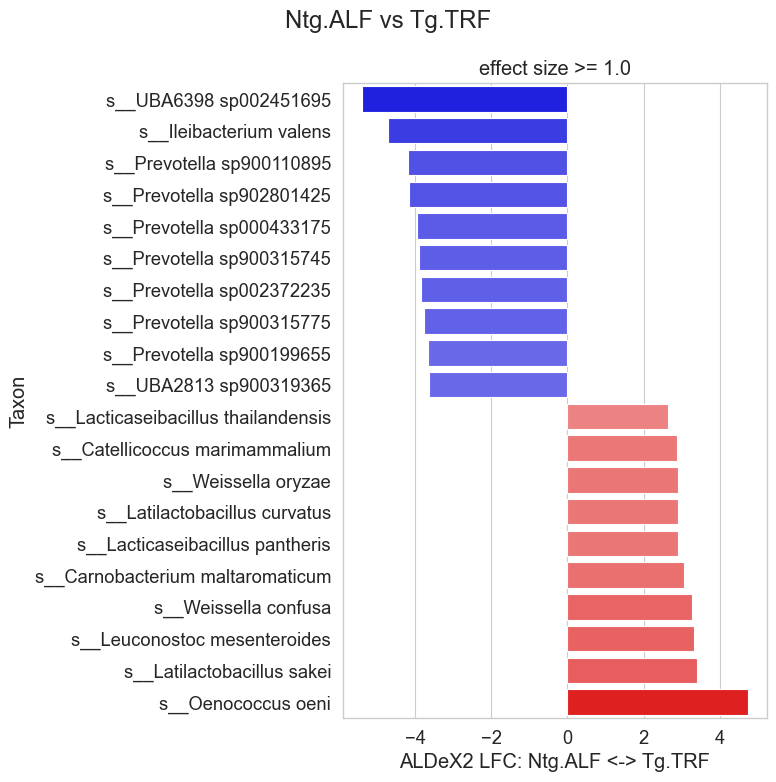

Tg.TRF Tg.ALF
424


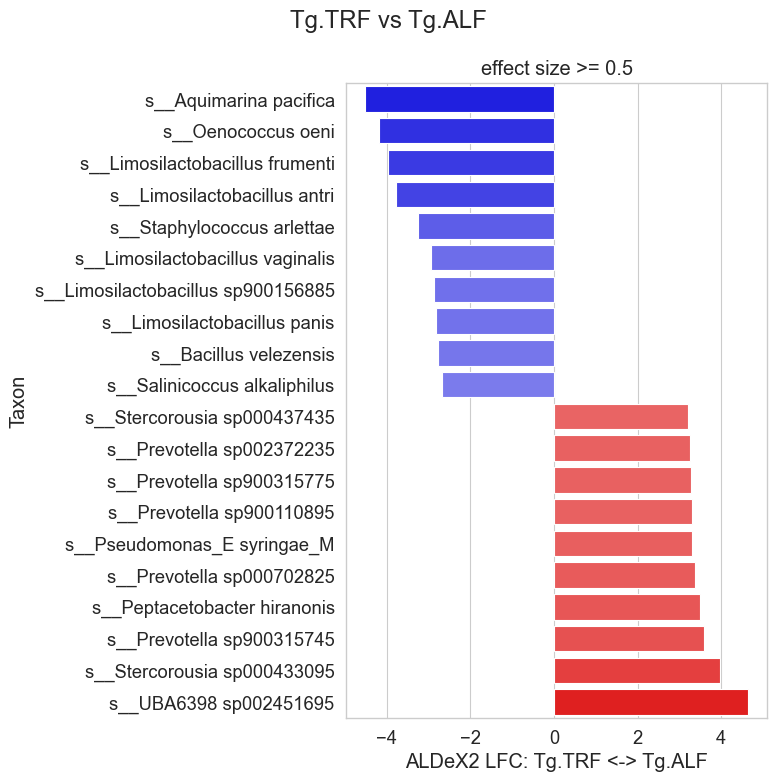

149


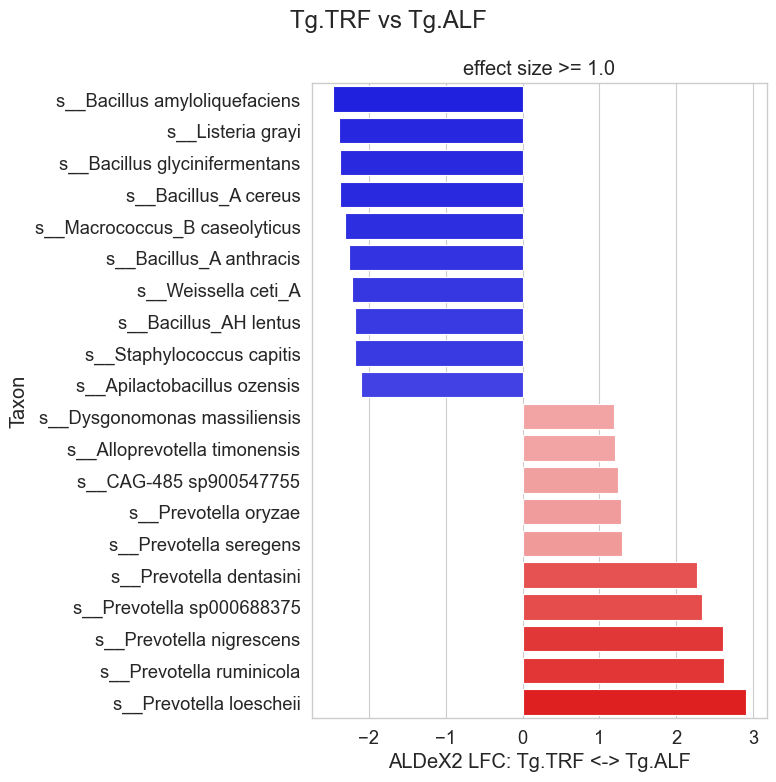

In [12]:
sig_taxa = {
    'species': set(),
}
for l in lfc_tables:
    #(sex, level, _) = l.stem.split('.', maxsplit=2)
    #print(f'{sex} {level}')

    lfc = pd.read_csv(l)
    id_col = lfc.columns[0]
    lfc['taxonomy'] = lfc[id_col].str.replace(r'^.*; ',r'', regex=True)
    lfc = lfc[~lfc.taxonomy.str.endswith('__')]  # drop unassigned
    sub_lfc = lfc.set_index('taxonomy', verify_integrity=True)
    left = lfc.columns[6][8:]
    right = lfc.columns[7][8:]
    if (left, right) not in display_orders:
        left, right = right, left
        sub_lfc['diff.btw'] = -sub_lfc['diff.btw']
    print(f'{left} {right}')
    for q_value in (0.5, 1.0):
        significant_lfc = sub_lfc[(sub_lfc['effect'].abs() >= q_value ) & (sub_lfc['diff.btw'].abs() >= 1)].sort_values('diff.btw')
        print(len(significant_lfc))
        if len(significant_lfc)>0:
            fig, ax = plt.subplots(figsize=(8,8))
            ax = diff_plot(data=significant_lfc, x='diff.btw')
            plt.suptitle(f'{left} vs {right}')
            plt.title(f'effect size >= {q_value}')
            ax.set_xlabel(f'ALDeX2 LFC: {left} <-> {right}')
            ax.set_ylabel('Taxon')
            plt.tight_layout()
            plt.savefig(f'/mnt/zarrinpar/scratch/sfloresr/AD_EM/metagenomics/aldex/figures/metagenomic.taxonomic.aldex2.{left}v{right}.q{q_value}.svg')
            plt.show()
            if q_value == 1.0:
                sig_taxa["species"].update(list(significant_lfc[id_col]))


# Box plots

In [9]:
genotype_diet_order = ['Ntg.ALF', 'Tg.ALF', 'Tg.TRF']
genotype_diet_groups = [
    ['Ntg.ALF', 'Tg.ALF', 'Tg.TRF'],
    ['Ntg.ALF', 'Tg.ALF'],
    ['Tg.ALF', 'Tg.TRF'],
]
genotype_diet_comparisions = list(combinations(genotype_diet_order, 2))

genotype_diet_palette = {
    'Tg.ALF': 'purple',
    'Ntg.ALF': 'orange',
    'Tg.TRF': 'green',
}
genotype_diet_palette_dark = {
    'Tg.ALF': 'darkmagenta',
    'Ntg.ALF': 'darkorange',
    'Tg.TRF': 'darkgreen',
}

In [10]:
taxa_of_interest = {
    'family': [
        "d__Bacteria; p__Bacteroidota; c__Bacteroidia; o__Bacteroidales; f__Bacteroidaceae",
        "d__Bacteria; p__Bacteroidota; c__Bacteroidia; o__Bacteroidales; f__Muribaculaceae",
        "d__Bacteria; p__Firmicutes; c__Bacilli; o__Haloplasmatales_A; f__Turicibacteraceae",
        "d__Bacteria; p__Firmicutes; c__Bacilli; o__Lactobacillales; f__Aerococcaceae",
        "d__Bacteria; p__Firmicutes; c__Bacilli; o__Lactobacillales; f__Carnobacteriaceae",
        "d__Bacteria; p__Firmicutes; c__Bacilli; o__Lactobacillales; f__Lactobacillaceae",
        "d__Bacteria; p__Firmicutes_A; c__Clostridia; o__Lachnospirales; f__Lachnospiraceae",        
    ],
    'species': [
        "d__Bacteria; p__Bacteroidota; c__Bacteroidia; o__Bacteroidales; f__Bacteroidaceae; g__Prevotella; s__Prevotella copri",
        "d__Bacteria; p__Bacteroidota; c__Bacteroidia; o__Bacteroidales; f__Bacteroidaceae; g__Prevotella; s__Prevotella sp002372235",
        "d__Bacteria; p__Bacteroidota; c__Bacteroidia; o__Bacteroidales; f__Bacteroidaceae; g__UBA6398; s__UBA6398 sp002451695",
        "d__Bacteria; p__Bacteroidota; c__Bacteroidia; o__Bacteroidales; f__Muribaculaceae; g__Paramuribaculum; s__Paramuribaculum sp001701115",
        "d__Bacteria; p__Bacteroidota; c__Bacteroidia; o__Bacteroidales; f__Tannerellaceae; g__Parabacteroides; s__Parabacteroides goldsteinii",
        "d__Bacteria; p__Firmicutes; c__Bacilli; o__Erysipelotrichales; f__Erysipelotrichaceae; g__Faecalibaculum; s__Faecalibaculum rodentium",
        "d__Bacteria; p__Firmicutes; c__Bacilli; o__Haloplasmatales_A; f__Turicibacteraceae; g__Turicibacter; s__Turicibacter sanguinis",
        "d__Bacteria; p__Firmicutes; c__Bacilli; o__Haloplasmatales_A; f__Turicibacteraceae; g__Turicibacter; s__Turicibacter sp001543345",
        "d__Bacteria; p__Firmicutes; c__Bacilli; o__Lactobacillales; f__Lactobacillaceae; g__Limosilactobacillus; s__Limosilactobacillus fermentum",
        "d__Bacteria; p__Firmicutes_A; c__Clostridia; o__Lachnospirales; f__Lachnospiraceae; g__Bilifractor; s__Bilifractor sp000702845",
        "d__Bacteria; p__Firmicutes; c__Bacilli; o__Lactobacillales; f__Lactobacillaceae; g__Lacticaseibacillus; s__Lacticaseibacillus paracasei",
        "d__Bacteria; p__Firmicutes; c__Bacilli; o__Lactobacillales; f__Lactobacillaceae; g__Limosilactobacillus; s__Limosilactobacillus antri",
    ],
}

In [11]:
md = pd.read_csv('stool.metagenomic.metadata.with_amyloid.tsv', sep='\t', index_col=0)

In [12]:
genotype_diet_comparisions

[('Ntg.ALF', 'Tg.ALF'), ('Ntg.ALF', 'Tg.TRF'), ('Tg.ALF', 'Tg.TRF')]

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Ntg.ALF vs. Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:6.830e-01 U_stat=1.058e+03
Tg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:9.816e-01 U_stat=1.329e+03
Ntg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:8.293e-01 U_stat=1.022e+03


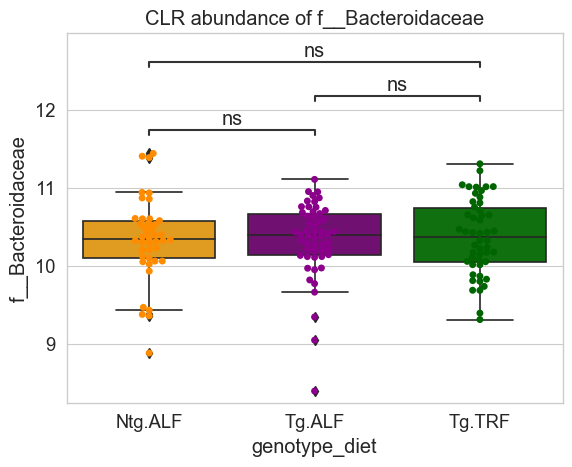

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Ntg.ALF vs. Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:4.604e-01 U_stat=1.212e+03
Tg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:2.956e-01 U_stat=1.484e+03
Ntg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:8.676e-02 U_stat=1.269e+03


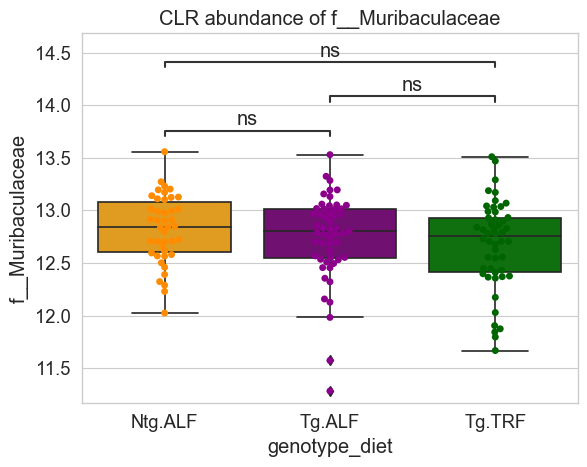

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Ntg.ALF vs. Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:3.711e-08 U_stat=1.848e+03
Tg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:1.218e-01 U_stat=1.090e+03
Ntg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:7.179e-05 U_stat=1.557e+03


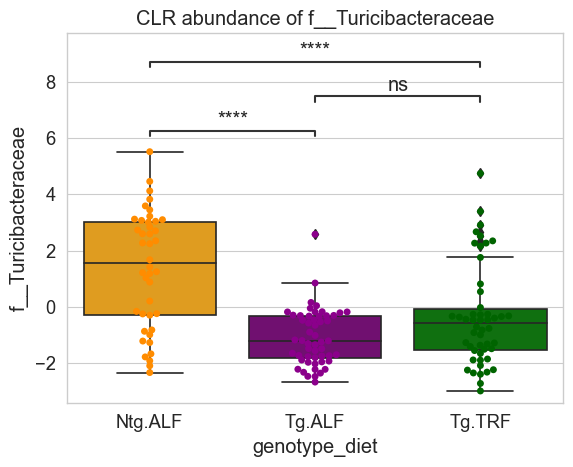

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Ntg.ALF vs. Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:9.075e-01 U_stat=1.129e+03
Tg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:3.551e-11 U_stat=3.210e+02
Ntg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:4.032e-09 U_stat=2.990e+02


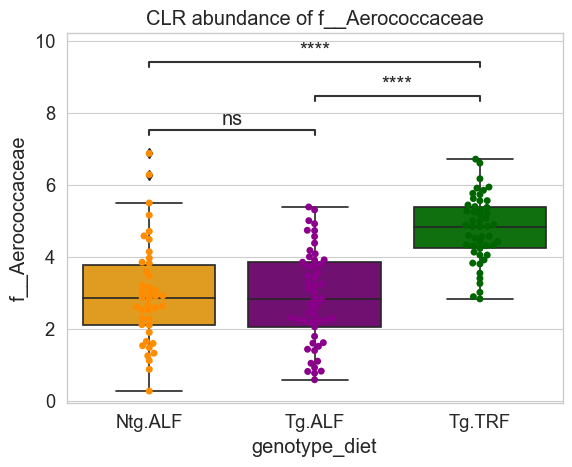

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Ntg.ALF vs. Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:9.492e-01 U_stat=1.122e+03
Tg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:2.168e-11 U_stat=3.100e+02
Ntg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:2.065e-09 U_stat=2.850e+02


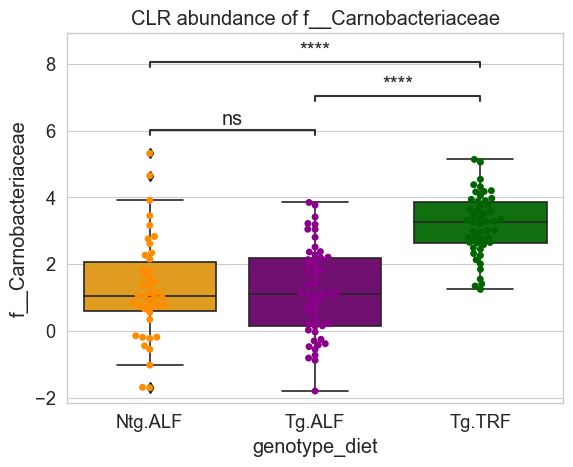

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Ntg.ALF vs. Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:5.364e-01 U_stat=1.196e+03
Tg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:3.248e-11 U_stat=3.190e+02
Ntg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:3.667e-09 U_stat=2.970e+02


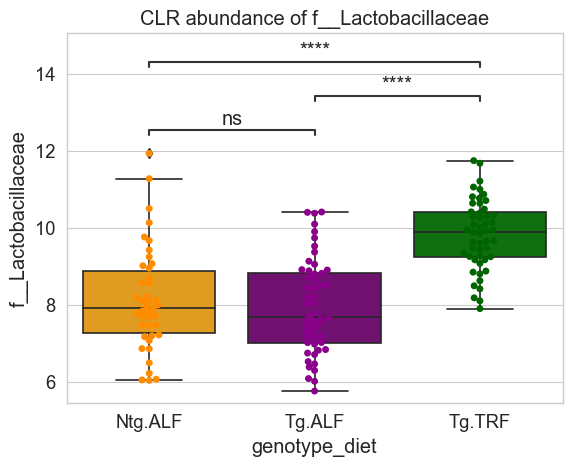

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Ntg.ALF vs. Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:1.645e-01 U_stat=9.270e+02
Tg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:2.777e-01 U_stat=1.490e+03
Ntg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:9.219e-01 U_stat=1.037e+03


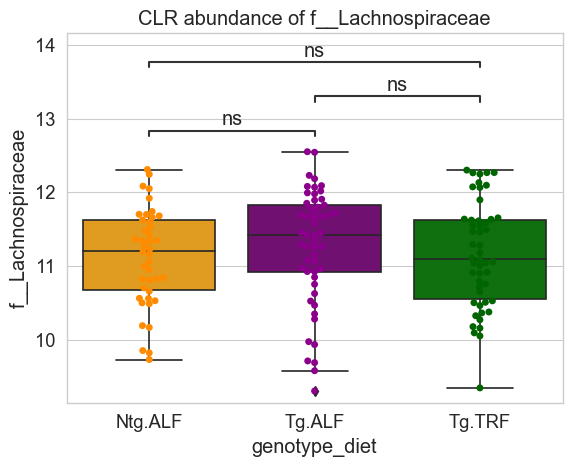

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Ntg.ALF vs. Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:2.993e-01 U_stat=1.252e+03
Tg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:1.423e-02 U_stat=1.697e+03
Ntg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:6.226e-04 U_stat=1.487e+03


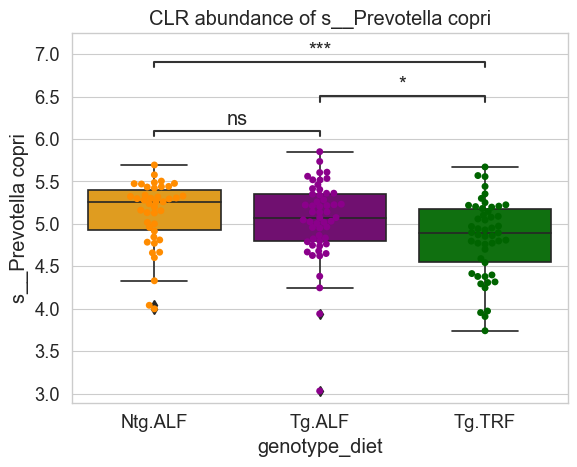

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Ntg.ALF vs. Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:2.626e-01 U_stat=1.263e+03
Tg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:4.373e-09 U_stat=2.215e+03
Ntg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:5.209e-11 U_stat=1.888e+03


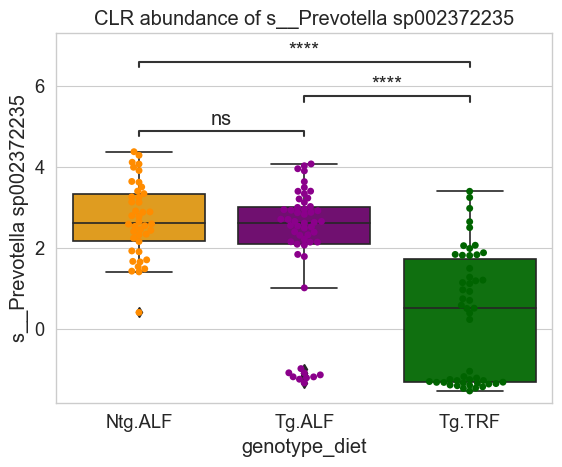

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Ntg.ALF vs. Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:2.233e-01 U_stat=1.276e+03
Tg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:1.470e-09 U_stat=2.242e+03
Ntg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:9.382e-12 U_stat=1.920e+03


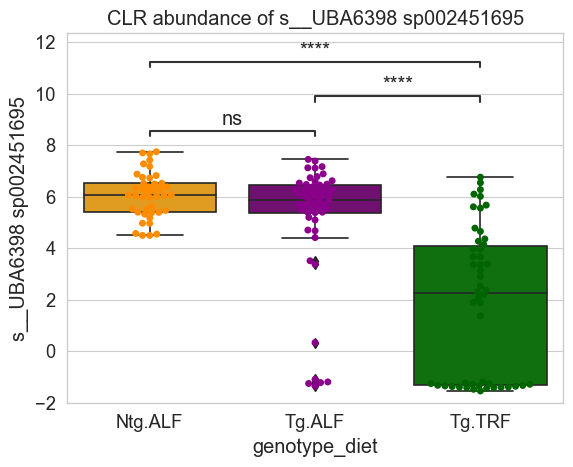

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Ntg.ALF vs. Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:4.498e-05 U_stat=5.680e+02
Tg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:2.169e-04 U_stat=1.886e+03
Ntg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:9.844e-01 U_stat=1.047e+03


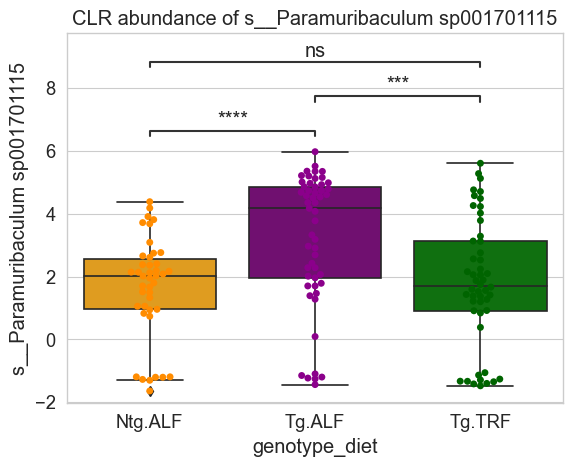

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Ntg.ALF vs. Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:8.720e-01 U_stat=1.135e+03
Tg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:4.100e-04 U_stat=7.890e+02
Ntg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:1.884e-03 U_stat=6.530e+02


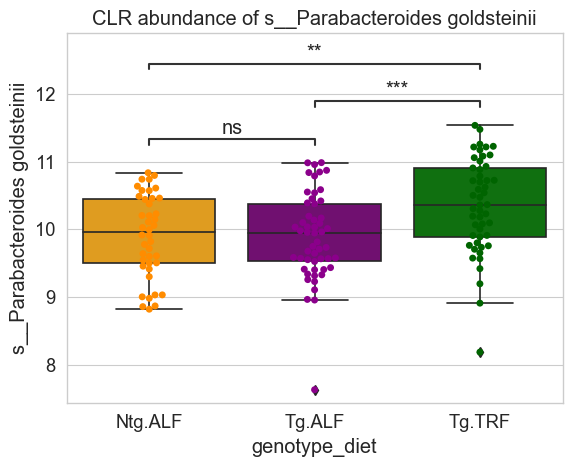

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Ntg.ALF vs. Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:5.453e-05 U_stat=1.652e+03
Tg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:1.494e-01 U_stat=1.544e+03
Ntg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:1.106e-06 U_stat=1.672e+03


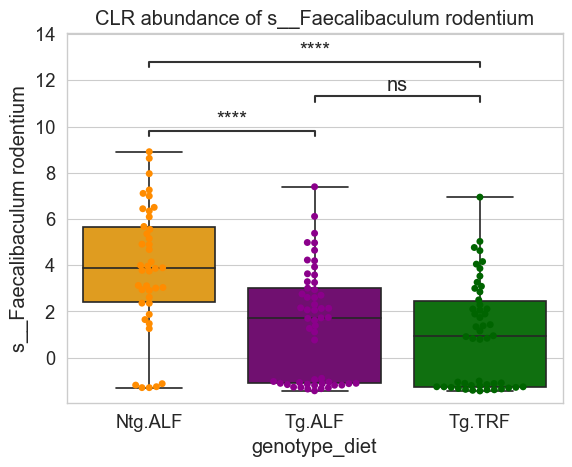

/opt/anaconda3/envs/qiime2-2023.7/lib/python3.8/site-packages/seaborn/categorical.py:1296: UserWarning: 9.4% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Ntg.ALF vs. Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:6.695e-08 U_stat=1.834e+03
Tg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:1.140e-01 U_stat=1.565e+03
Ntg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:3.414e-07 U_stat=1.701e+03


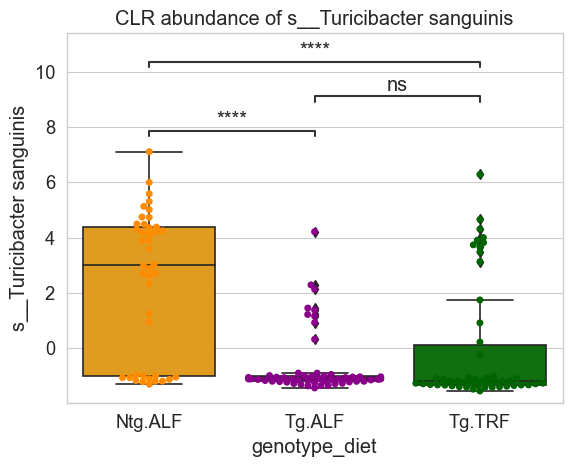

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Ntg.ALF vs. Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:5.180e-09 U_stat=1.893e+03
Tg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:6.048e-02 U_stat=1.040e+03
Ntg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:2.891e-05 U_stat=1.584e+03


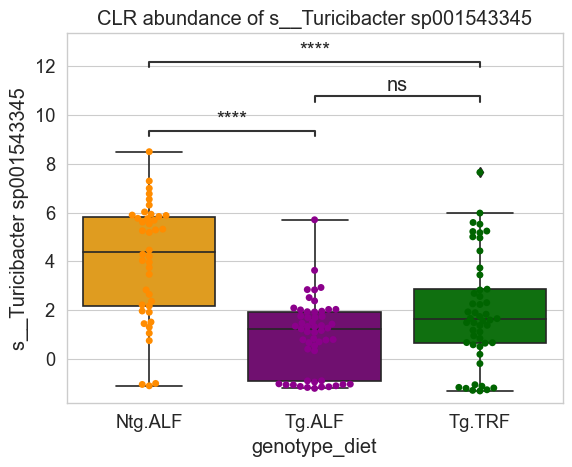

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Ntg.ALF vs. Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:6.395e-01 U_stat=1.176e+03
Tg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:1.724e-10 U_stat=3.570e+02
Ntg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:6.456e-09 U_stat=3.090e+02


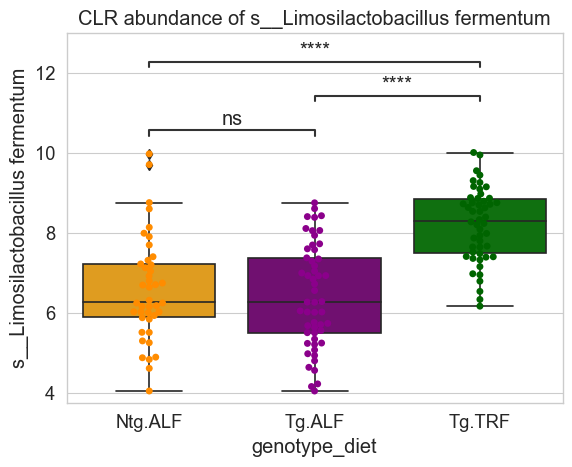

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Ntg.ALF vs. Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:3.470e-05 U_stat=5.600e+02
Tg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:6.277e-01 U_stat=1.399e+03
Ntg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:4.135e-04 U_stat=5.990e+02


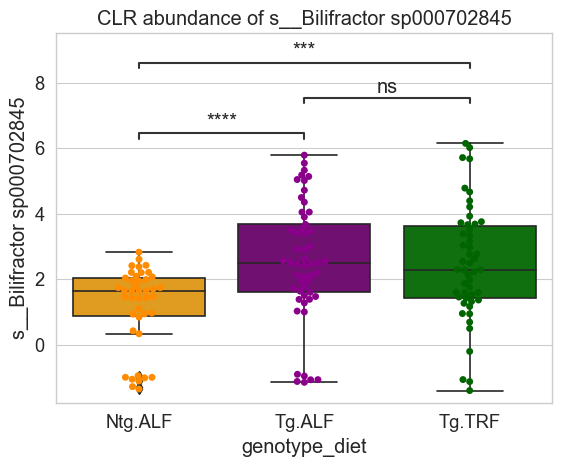

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Ntg.ALF vs. Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:7.558e-01 U_stat=1.071e+03
Tg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:4.579e-08 U_stat=4.960e+02
Ntg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:1.674e-07 U_stat=3.820e+02


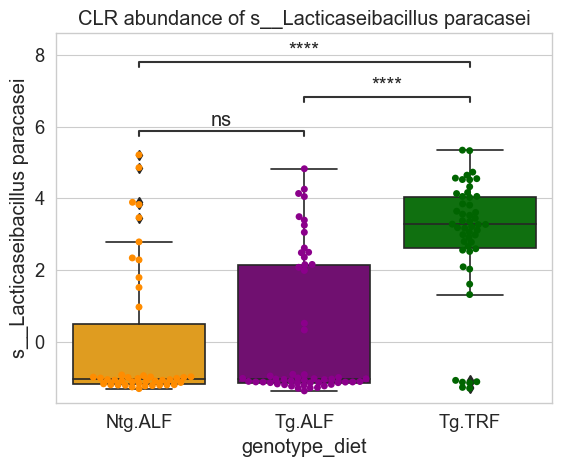

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Ntg.ALF vs. Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:2.822e-01 U_stat=1.257e+03
Tg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:4.204e-04 U_stat=7.900e+02
Ntg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:1.235e-01 U_stat=8.530e+02


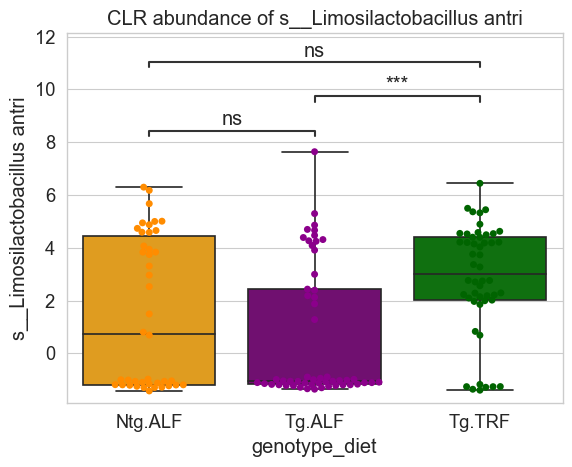

In [13]:
# per_sample CLR
for level, taxa in taxa_of_interest.items():
    counts = pd.read_csv(f'metagenomic/159013_wolR2_per_genome.feature-table.{level}.csv', index_col=0)
    per_sample_prop = counts/counts.sum()
    per_sample_clr = pd.DataFrame(
        clr(multiplicative_replacement(per_sample_prop.T.to_numpy())),
        columns=per_sample_prop.index,
        index=per_sample_prop.columns
    ).T
    per_sample_clr.loc[taxa].to_csv(f'metagenomic/159013_wolR2_per_genome.feature-table.{level}.clr.filtered_taxa.csv')

    per_mouse = counts.T.join(md.mouse_id).groupby('mouse_id').agg(np.mean).T
    per_mouse_prop = per_mouse/per_mouse.sum()
    per_mouse_clr = pd.DataFrame(
        clr(multiplicative_replacement(per_mouse_prop.T.to_numpy())),
        columns=per_mouse_prop.index,
        index=per_mouse_prop.columns
    ).T
    
    for t in taxa:
        taxon = t[t.rindex("; ")+2:]
        row = per_sample_clr.loc[t]
        row.name = taxon
        sub_md = md.join(row)
        plot_args = {
            'data': sub_md,
            'y': taxon,
            'x': 'genotype_diet',
            'order': genotype_diet_order,
        }
        ax = sns.boxplot(
            **plot_args,
            palette=genotype_diet_palette,
        )
        ax = sns.swarmplot(
            **plot_args,
            palette=genotype_diet_palette_dark,
            ax=ax
        )
        annotator = Annotator(ax, genotype_diet_comparisions, **plot_args)  # add statistics
        annotator.configure(test='Mann-Whitney', text_format='star', loc='inside')
        annotator.apply_and_annotate()
        plt.title(f'CLR abundance of {taxon}')
        plt.savefig(f'images/metagenomic.clr_abundance.{taxon.replace(" ", "_")}.svg')
        plt.show()

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Ntg.ALF vs. Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:4.698e-01 U_stat=2.400e+01
Tg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:7.239e-01 U_stat=4.500e+01
Ntg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:7.577e-01 U_stat=2.800e+01


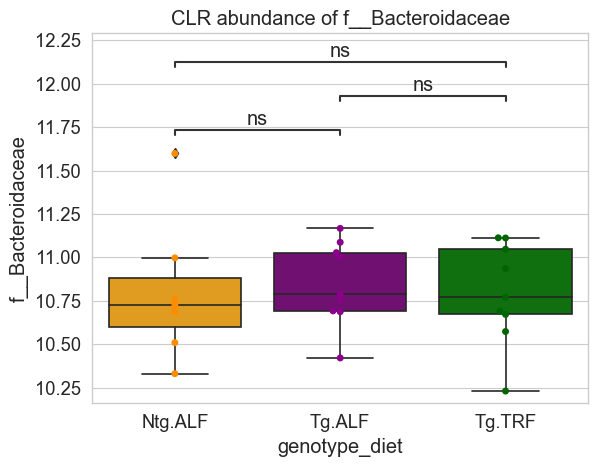

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Ntg.ALF vs. Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:9.182e-01 U_stat=3.300e+01
Tg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:4.799e-01 U_stat=4.900e+01
Ntg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:4.698e-01 U_stat=3.900e+01


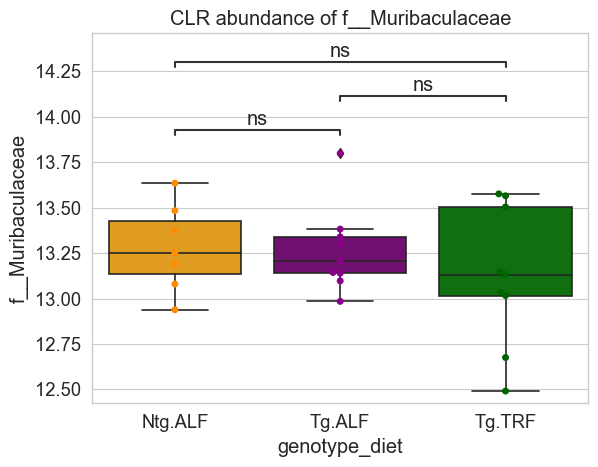

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Ntg.ALF vs. Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:7.115e-02 U_stat=4.900e+01
Tg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:2.893e-01 U_stat=2.800e+01
Ntg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:2.991e-01 U_stat=4.200e+01


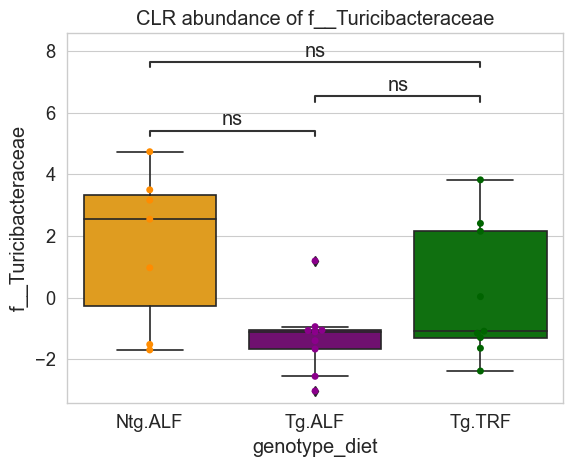

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Ntg.ALF vs. Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:3.510e-01 U_stat=2.200e+01
Tg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:1.086e-03 U_stat=3.000e+00
Ntg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:1.643e-02 U_stat=9.000e+00


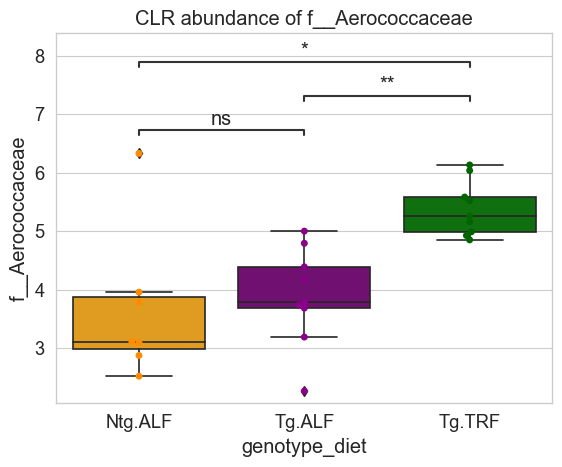

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Ntg.ALF vs. Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:3.510e-01 U_stat=2.200e+01
Tg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:1.086e-03 U_stat=3.000e+00
Ntg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:1.643e-02 U_stat=9.000e+00


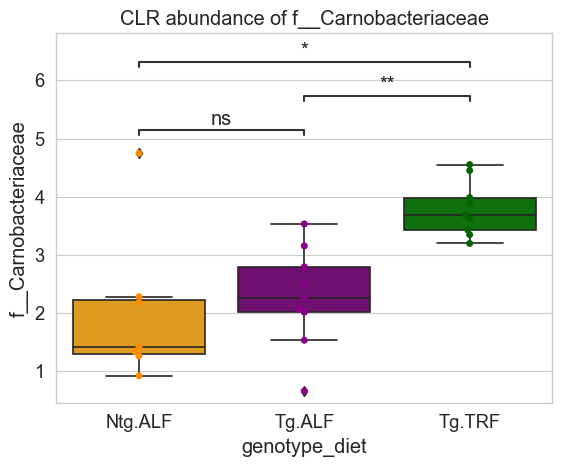

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Ntg.ALF vs. Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:2.991e-01 U_stat=2.100e+01
Tg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:1.086e-03 U_stat=3.000e+00
Ntg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:1.643e-02 U_stat=9.000e+00


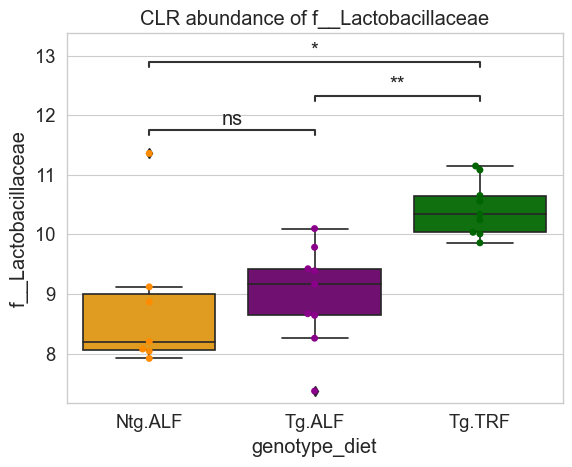

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Ntg.ALF vs. Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:2.991e-01 U_stat=2.100e+01
Tg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:5.962e-01 U_stat=4.700e+01
Ntg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:1.000e+00 U_stat=3.100e+01


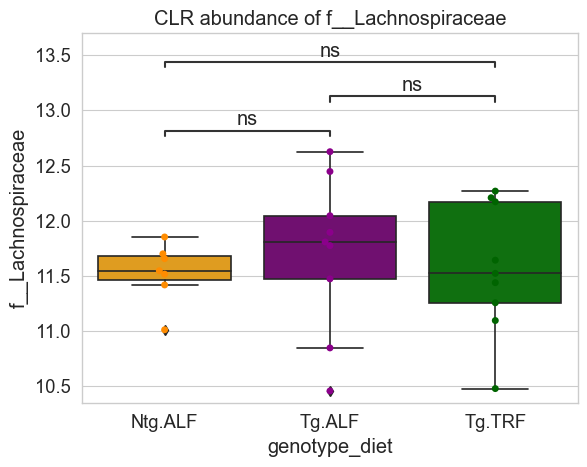

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Ntg.ALF vs. Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:3.510e-01 U_stat=4.100e+01
Tg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:3.314e-01 U_stat=5.200e+01
Ntg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:5.490e-02 U_stat=5.000e+01


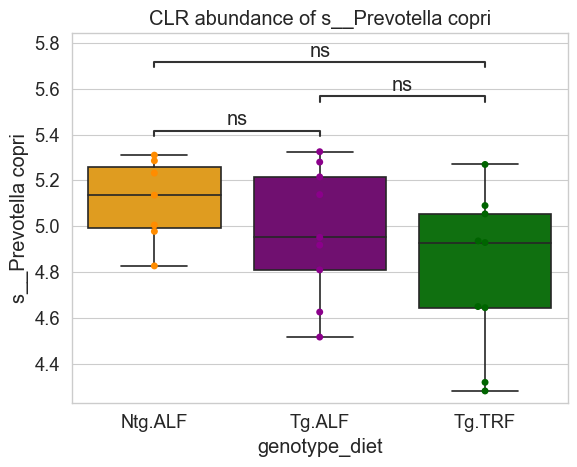

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Ntg.ALF vs. Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:8.371e-01 U_stat=3.400e+01
Tg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:1.342e-02 U_stat=6.900e+01
Ntg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:3.322e-03 U_stat=5.800e+01


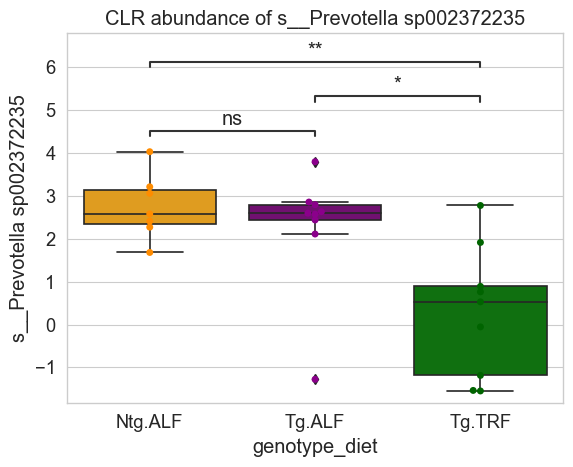

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Ntg.ALF vs. Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:6.065e-01 U_stat=3.700e+01
Tg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:2.168e-02 U_stat=6.700e+01
Ntg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:3.322e-03 U_stat=5.800e+01


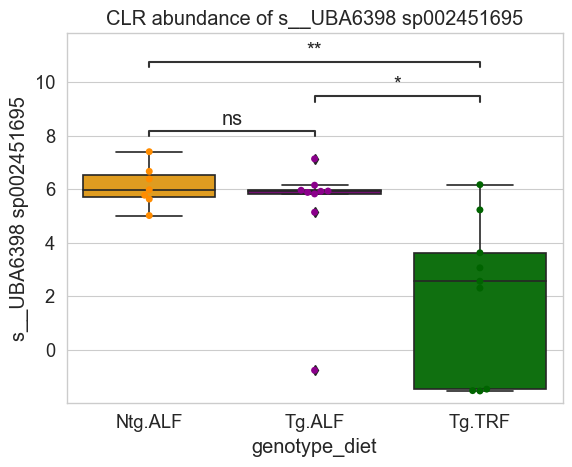

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Ntg.ALF vs. Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:7.115e-02 U_stat=1.400e+01
Tg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:1.577e-01 U_stat=5.700e+01
Ntg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:1.000e+00 U_stat=3.200e+01


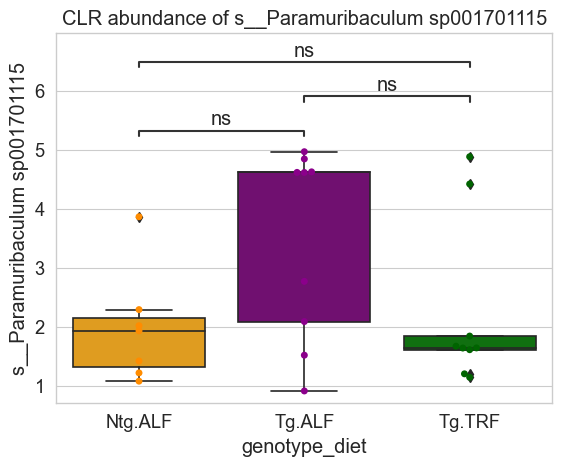

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Ntg.ALF vs. Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:8.371e-01 U_stat=3.400e+01
Tg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:2.728e-02 U_stat=1.500e+01
Ntg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:3.112e-02 U_stat=1.100e+01


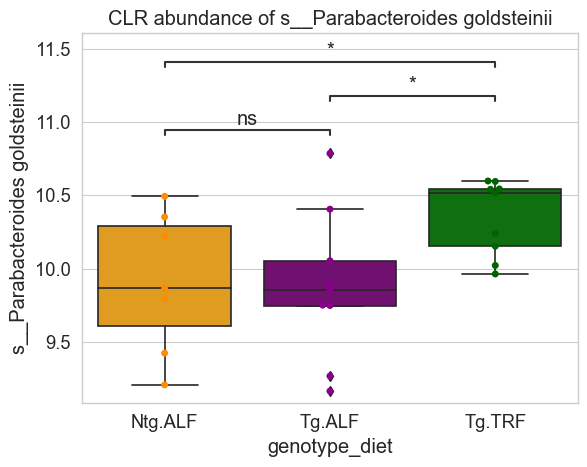

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Ntg.ALF vs. Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:1.416e-01 U_stat=4.600e+01
Tg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:5.962e-01 U_stat=4.700e+01
Ntg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:1.643e-02 U_stat=5.400e+01


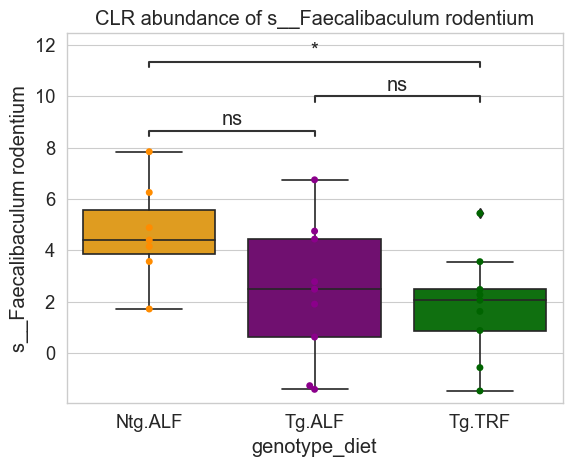

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Ntg.ALF vs. Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:2.290e-02 U_stat=5.300e+01
Tg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:1.000e+00 U_stat=4.000e+01
Ntg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:7.115e-02 U_stat=4.900e+01


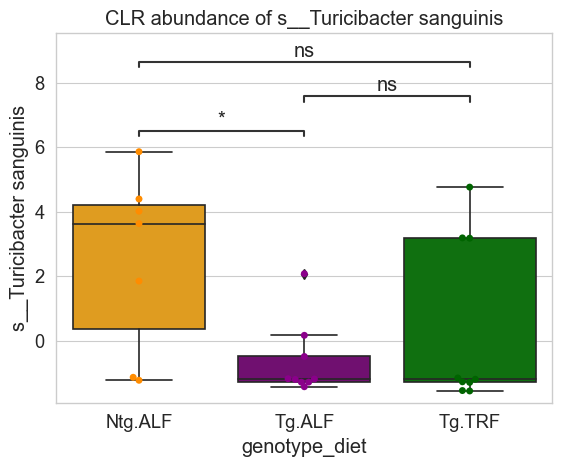

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Ntg.ALF vs. Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:4.178e-02 U_stat=5.100e+01
Tg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:2.893e-01 U_stat=2.800e+01
Ntg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:1.416e-01 U_stat=4.600e+01


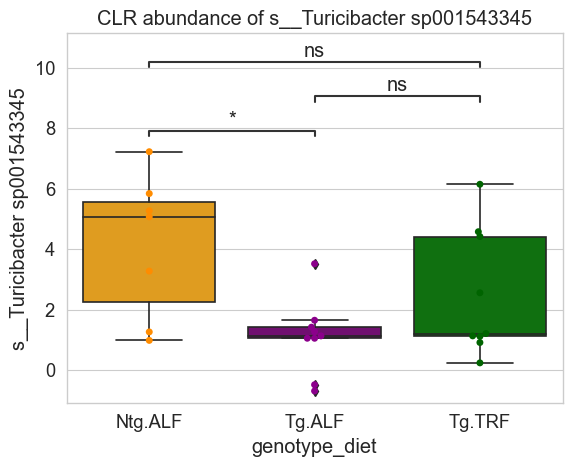

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Ntg.ALF vs. Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:2.991e-01 U_stat=2.100e+01
Tg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:7.923e-04 U_stat=2.000e+00
Ntg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:1.643e-02 U_stat=9.000e+00


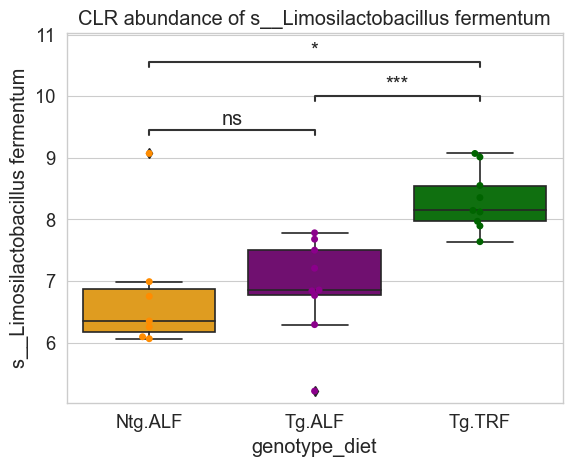

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Ntg.ALF vs. Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:9.073e-02 U_stat=1.500e+01
Tg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:7.911e-01 U_stat=4.400e+01
Ntg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:3.112e-02 U_stat=1.100e+01


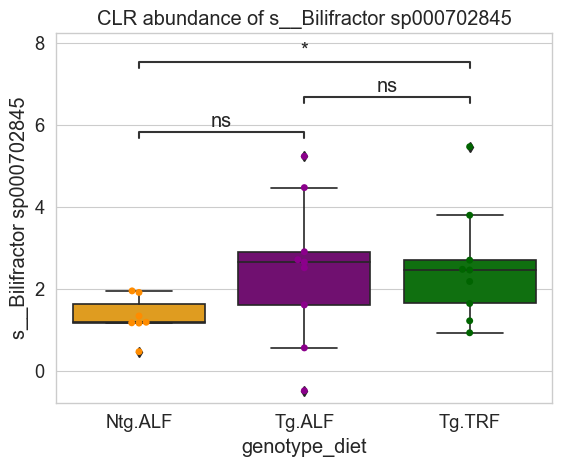

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Ntg.ALF vs. Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:3.510e-01 U_stat=2.200e+01
Tg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:4.718e-03 U_stat=8.000e+00
Ntg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:1.154e-02 U_stat=8.000e+00


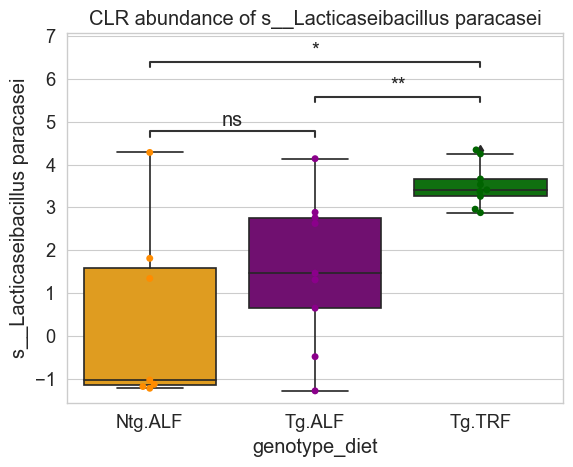

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

Ntg.ALF vs. Tg.ALF: Mann-Whitney-Wilcoxon test two-sided, P_val:9.182e-01 U_stat=3.300e+01
Tg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:2.728e-02 U_stat=1.500e+01
Ntg.ALF vs. Tg.TRF: Mann-Whitney-Wilcoxon test two-sided, P_val:2.991e-01 U_stat=2.100e+01


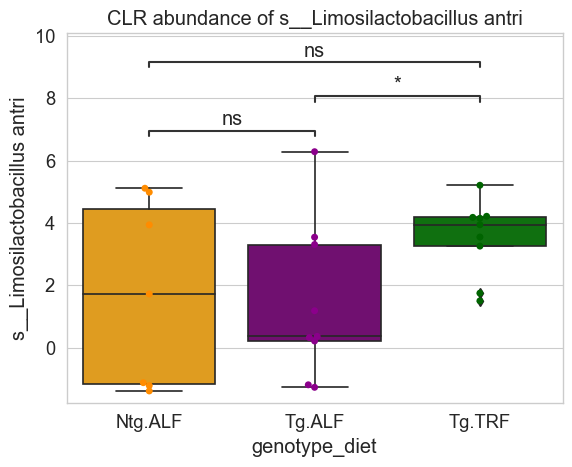

In [14]:
# per_mouse CLR
for level, taxa in taxa_of_interest.items():
    counts = pd.read_csv(f'metagenomic/159013_wolR2_per_genome.feature-table.{level}.csv', index_col=0)

    per_mouse = counts.T.join(md.mouse_id).groupby('mouse_id').agg(np.mean).T
    per_mouse_prop = per_mouse/per_mouse.sum()
    per_mouse_clr = pd.DataFrame(
        clr(multiplicative_replacement(per_mouse_prop.T.to_numpy())),
        columns=per_mouse_prop.index,
        index=per_mouse_prop.columns
    ).T
    mouse_md = md[['mouse_id', 'genotype_diet']].drop_duplicates().set_index('mouse_id')
    for t in taxa:
        taxon = t[t.rindex("; ")+2:]
        row = per_mouse_clr.loc[t]
        row.name = taxon
        sub_md = mouse_md.join(row)
        plot_args = {
            'data': sub_md,
            'y': taxon,
            'x': 'genotype_diet',
            'order': genotype_diet_order,
        }
        ax = sns.boxplot(
            **plot_args,
            palette=genotype_diet_palette,
        )
        ax = sns.swarmplot(
            **plot_args,
            palette=genotype_diet_palette_dark,
            ax=ax
        )
        annotator = Annotator(ax, genotype_diet_comparisions, **plot_args)  # add statistics
        annotator.configure(test='Mann-Whitney', text_format='star', loc='inside')
        annotator.apply_and_annotate()
        plt.title(f'CLR abundance of {taxon}')
        plt.savefig(f'images/metagenomic.per_mouse_mean.clr_abundance.{taxon.replace(" ", "_")}.svg')
        plt.show()